# ViHSD — chạy lại m-BERT và đối chứng với PhoBERT
Notebook bổ sung cho đồ án, chạy độc lập trên Colab T4. Giữ nguyên notebook/kết quả 68,20% trước đây để truy vết; không trộn các lượt chạy.

**Ba thực nghiệm mặc định, tổng 10 epoch:**
1. `paper_aligned_mbert`: m-BERT cased, 4 epoch, batch 16, độ dài 100, seed 4; checkpoint cuối theo cách chạy trong mã nguồn tác giả. Đây là chạy bám cấu hình công bố trên thư viện hiện đại, **không phải môi trường lịch sử được tái lập hoàn toàn**.
2. `controlled_mbert`: m-BERT, tiền xử lý chung, 3 epoch, batch 16, độ dài 128, LR 2e-5, seed 42; chọn checkpoint theo MF1 Dev.
3. `controlled_phobert`: PhoBERT, cùng quy định với bước 2; tokenizer và kiến trúc theo mô hình.

Mọi mô hình học từ Train; Dev chỉ chọn checkpoint trong nhánh đối chứng. Tất cả cấu hình được khóa trước khi tính điểm Test. Không hứa tái tạo đúng 62,69% hoặc 68,20%.

## 1. Đọc nguồn và xác định giới hạn tái lập
Nguồn chính: [bài báo v4](https://arxiv.org/abs/2103.11528v4), [notebook tác giả](https://github.com/sonlam1102/vihsd/blob/826ef5efdda8f397e8b76b1ac26e05edda20ded6/ViHSD_multilingual_Transformers.ipynb), [Trainer](https://huggingface.co/docs/transformers/main_classes/trainer), [VinAI PhoBERT](https://huggingface.co/vinai/phobert-base-v2).

| Hạng mục | Bằng chứng nguồn | Notebook này |
|---|---|---|
| m-BERT cased | bert-base-multilingual-cased; batch 16; max length 100; 4 epoch; seed 4 | Giữ các giá trị công bố ở nhánh paper_aligned |
| Phiên bản | Tác giả cài transformers==4.3.0; SimpleTransformers không khóa phiên bản | Dùng Transformers hiện đại được khóa phiên bản; ghi rõ khác biệt |
| Checkpoint | evaluate_during_training=False; train xong rồi eval Test | Nhánh paper_aligned chọn mô hình cuối; đối chứng chọn theo Dev |
| Tiền xử lý trong code | Giữ hoa/thường, PyVi, file vietnamese-stopwords-dash.txt, bỏ một số vùng emoji | File dash gốc không kèm notebook; dùng danh sách công khai chuyển khoảng trắng thành `_`, là phương án thay thế |
| Tiền xử lý trong bài | Có loại URL/hashtag/mention | Hàm code công khai không thể hiện bước này; nhánh paper_aligned đi theo hàm code, không âm thầm gộp hai mô tả |
| Tham số không đặt | Code không đặt learning rate/optimizer/warmup | Chọn tường minh LR 4e-5, AdamW, warmup 0,06; dựa vào mặc định SimpleTransformers hiện tại, không khẳng định là mặc định năm 2021 |
| Split | Bài mô tả 7:1:2 | Dùng ZIP được pin commit, kiểm tra số thực tế 72/8/20; không tự chia lại rồi gọi là split bài báo |

Vì khác môi trường, stopword và chưa xác nhận split lịch sử, kết quả nhánh đầu chỉ được gọi là **kết quả chạy bám cấu hình công bố**. Không cố cài thư viện 2021 vào Colab hiện đại rồi coi đó là môi trường gốc.

## 2. Độ đo và quy tắc trước huấn luyện
- Chính: Macro F1, trung bình F1 của CLEAN/OFFENSIVE/HATE; phụ: Weighted F1, Accuracy và Precision/Recall/F1/support từng lớp, confusion matrix 3×3. Dùng đủ labels=[0,1,2], zero_division=0.
- Nhánh đối chứng có cùng split, văn bản tiền xử lý, seed, batch, LR, optimizer, epoch tối đa và cách chọn checkpoint; chỉ thay mô hình/tokenizer. Cùng giới hạn 128 token không đồng nghĩa cùng lượng văn bản vì tokenizer khác nhau; lưu tỷ lệ truncation Train/Dev.
- Đây là so sánh dưới ngân sách cố định, không phải tìm cấu hình tối ưu riêng cho từng mô hình. Đường học theo epoch không phải tìm siêu tham số.
- Mỗi cấu hình đã khóa chỉ suy luận Test một lần mỗi lượt chạy. Phân tích Test sau đó chỉ để giải thích, không quay lại chỉnh cấu hình.
- Báo thời gian xử lý, tokenization, train (gồm Dev/checkpoint), Test và bộ nhớ GPU; không trộn các phép đo khác phạm vi.
- `SEEDS=[42]` là một lượt đối chứng, chưa đo độ ổn định. Có thể quyết định trước `[42,43,44]` để báo trung bình ± std. Bật ablation là tăng ngân sách có công bố.

In [1]:
%pip install -q "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.10.1" "pyvi==0.1.1" "scikit-learn==1.6.1" "numpy>=1.26,<3" "pandas>=2.2,<3" matplotlib seaborn "torch>=2.6,<3"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


Sau cài đặt, nếu Colab yêu cầu restart, chọn Restart session rồi chạy từ ô import bên dưới. Chọn Runtime → Change runtime type → T4 GPU. Không bấm chạy notebook cũ để tiếp tục lấy biến vì notebook này độc lập.

In [2]:
import os, io, re, json, time, random, hashlib, zipfile, unicodedata, html, gc, platform
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version, PackageNotFoundError
import numpy as np
import pandas as pd
from pyvi import ViTokenizer
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT=Path('vihsd_comparison'); ROOT.mkdir(exist_ok=True)
RUN_DIR=ROOT/time.strftime('%Y%m%d_%H%M%S'); RUN_DIR.mkdir(exist_ok=False)
LABELS=[0,1,2]; NAMES=['CLEAN','OFFENSIVE','HATE']
REPO_COMMIT='826ef5efdda8f397e8b76b1ac26e05edda20ded6'
SEEDS=[42]
RUN_ABLATION=False  # Quyết định trước khi chạy: thêm mỗi mô hình một nhánh bỏ chuẩn hóa nhiễu.
BOOTSTRAP_REPEATS=500

def save_json(name,obj):
    (RUN_DIR/name).write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')

def metrics(y,p):
    per=f1_score(y,p,labels=LABELS,average=None,zero_division=0)
    return dict(macro_f1=float(per.mean()),weighted_f1=float(f1_score(y,p,labels=LABELS,average='weighted',zero_division=0)),
                accuracy=float(accuracy_score(y,p)),**{f'f1_{n}':float(v) for n,v in zip(NAMES,per)})

## 3. Tải đúng dữ liệu, lưu hash và kiểm tra rò rỉ
Tải ZIP từ commit cố định của GitHub tác giả. Giữ 24.048 dòng Train gốc, kể cả 2 dòng văn bản rỗng, để không tự ý thay split; tokenizer có thể mã hóa chuỗi rỗng thành các token đặc biệt. Đây là khác biệt có ghi nhận so với notebook trước đã bỏ 2 dòng Train.

ID luôn gắn dòng nguồn; giữ văn bản nguyên bản trong CSV dự đoán. Không xóa nhãn mâu thuẫn hoặc trùng trong Test theo kết quả dự đoán. Chỉ kiểm tra văn bản chuẩn hóa NFC và khoảng trắng, phân biệt hoa/thường. Trùng gần nghĩa/khác hoa chưa được phát hiện.

In [3]:
DATA_URL=f'https://raw.githubusercontent.com/sonlam1102/vihsd/{REPO_COMMIT}/data/vihsd.zip'
archive=ROOT/'vihsd_pinned.zip'
if not archive.exists():
    with urlopen(DATA_URL,timeout=60) as r: archive.write_bytes(r.read())
blob=archive.read_bytes()
EXPECTED_SHA256='1d823c4c86a8aede83555c64da4e1be24146967aac6b30cdaf8603d4910f328d'
assert hashlib.sha256(blob).hexdigest()==EXPECTED_SHA256,'ZIP khác bản đã kiểm tra; xác minh nguồn trước khi tiếp tục.'
frames={}
with zipfile.ZipFile(io.BytesIO(blob)) as z:
    for split in ['train','dev','test']:
        df=pd.read_csv(z.open(f'vihsd/{split}.csv'),keep_default_na=False)
        assert {'free_text','label_id'}<=set(df.columns)
        df=df.rename(columns={'free_text':'text','label_id':'label'})
        assert df.label.isin(LABELS).all()
        df['label']=df.label.astype(int); df['text']=df.text.astype(str)
        df['id']=[f'{split}_{i:06d}' for i in range(len(df))]
        frames[split]=df[['id','text','label']].copy()
def text_key(s): return re.sub(r'\s+',' ',unicodedata.normalize('NFC',str(s))).strip()
keys={s:f.text.map(text_key) for s,f in frames.items()}
audit={s:{'rows':len(f),'empty':int(keys[s].eq('').sum()),'duplicate_rows':int(keys[s].duplicated().sum())} for s,f in frames.items()}
overlaps={a+'/'+b:len((set(keys[a])&set(keys[b]))-{''}) for a,b in [('train','dev'),('train','test'),('dev','test')]}
# Cùng một mặt nạ cho tất cả mô hình; chỉ dựa vào văn bản, không dùng nhãn Test để chọn mẫu.
seen_text=set(keys['train'])|set(keys['dev'])
UNSEEN_MASK=(~keys['test'].isin(seen_text)&keys['test'].ne('')).to_numpy()
manifest=dict(url=DATA_URL,commit=REPO_COMMIT,sha256=EXPECTED_SHA256,audit=audit,overlap_unique_text=overlaps,
              test_unseen_text_rows=int(UNSEEN_MASK.sum()),policy='Preserve original splits; also report Test subset unseen in Train/Dev')
save_json('data_manifest.json',manifest)
display(pd.DataFrame(audit).T); print('Trùng chéo:',overlaps)
print('Test chưa thấy trong Train/Dev:',int(UNSEEN_MASK.sum()),'/',len(UNSEEN_MASK))
print('LƯU Ý: tập con unseen không thay thế một bộ Test độc lập hoặc split theo nhóm; không chọn mô hình bằng điểm này.')
df_train,df_dev,df_test=[frames[s] for s in ['train','dev','test']]
y_train,y_dev=[frames[s].label.to_numpy() for s in ['train','dev']]
display(df_train.label.value_counts().reindex(LABELS).rename(index=dict(zip(LABELS,NAMES))))

,rows,empty,duplicate_rows
train,24048,2,1504
dev,2672,0,22
test,6680,0,106


Trùng chéo: {'train/dev': 321, 'train/test': 787, 'dev/test': 91}
Test chưa thấy trong Train/Dev: 5796 / 6680
LƯU Ý: tập con unseen không thay thế một bộ Test độc lập hoặc split theo nhóm; không chọn mô hình bằng điểm này.


,count
label,
CLEAN,19886
OFFENSIVE,1606
HATE,2556


## 4. Hai chính sách tiền xử lý
**paper_code_approx:** giữ hoa/thường → PyVi → lọc stopword → bỏ các vùng emoji giống hàm tác giả. Không thêm TEENCODE_DICT. File stopword gốc bị thiếu, nên dùng snapshot danh sách công khai đã nhúng bên dưới, thay khoảng trắng bằng `_`; không coi đây là file dash lịch sử.

**shared:** NFC → giữ dấu ẩn danh → URL/USER → bỏ thẻ HTML/ký tự điều khiển → chuẩn hóa khoảng trắng → PyVi, giữ hoa/thường, phủ định, emoji và từ tục. Cùng một chuỗi được đưa vào cả hai tokenizer. Không dùng từ điển teencode viết tay.

**minimal** cho ablation tùy chọn: NFC + khoảng trắng + PyVi, không thay URL/mention/HTML. Chỉ nhánh shared vs minimal được dùng để đo tác dụng gói chuẩn hóa này, không quy riêng cho một thao tác thành phần.

In [4]:
STOPWORD_SNAPSHOT = 'a lô\na ha\nai\nai ai\nai nấy\nai đó\nalô\namen\nanh\nanh ấy\nba\nba ba\nba bản\nba cùng\nba họ\nba ngày\nba ngôi\nba tăng\nbao giờ\nbao lâu\nbao nhiêu\nbao nả\nbay biến\nbiết\nbiết bao\nbiết bao nhiêu\nbiết chắc\nbiết chừng nào\nbiết mình\nbiết mấy\nbiết thế\nbiết trước\nbiết việc\nbiết đâu\nbiết đâu chừng\nbiết đâu đấy\nbiết được\nbuổi\nbuổi làm\nbuổi mới\nbuổi ngày\nbuổi sớm\nbà\nbà ấy\nbài\nbài bác\nbài bỏ\nbài cái\nbác\nbán\nbán cấp\nbán dạ\nbán thế\nbây bẩy\nbây chừ\nbây giờ\nbây nhiêu\nbèn\nbéng\nbên\nbên bị\nbên có\nbên cạnh\nbông\nbước\nbước khỏi\nbước tới\nbước đi\nbạn\nbản\nbản bộ\nbản riêng\nbản thân\nbản ý\nbất chợt\nbất cứ\nbất giác\nbất kì\nbất kể\nbất kỳ\nbất luận\nbất ngờ\nbất nhược\nbất quá\nbất quá chỉ\nbất thình lình\nbất tử\nbất đồ\nbấy\nbấy chầy\nbấy chừ\nbấy giờ\nbấy lâu\nbấy lâu nay\nbấy nay\nbấy nhiêu\nbập bà bập bõm\nbập bõm\nbắt đầu\nbắt đầu từ\nbằng\nbằng cứ\nbằng không\nbằng người\nbằng nhau\nbằng như\nbằng nào\nbằng nấy\nbằng vào\nbằng được\nbằng ấy\nbển\nbệt\nbị\nbị chú\nbị vì\nbỏ\nbỏ bà\nbỏ cha\nbỏ cuộc\nbỏ không\nbỏ lại\nbỏ mình\nbỏ mất\nbỏ mẹ\nbỏ nhỏ\nbỏ quá\nbỏ ra\nbỏ riêng\nbỏ việc\nbỏ xa\nbỗng\nbỗng chốc\nbỗng dưng\nbỗng không\nbỗng nhiên\nbỗng nhưng\nbỗng thấy\nbỗng đâu\nbộ\nbộ thuộc\nbộ điều\nbội phần\nbớ\nbởi\nbởi ai\nbởi chưng\nbởi nhưng\nbởi sao\nbởi thế\nbởi thế cho nên\nbởi tại\nbởi vì\nbởi vậy\nbởi đâu\nbức\ncao\ncao lâu\ncao ráo\ncao răng\ncao sang\ncao số\ncao thấp\ncao thế\ncao xa\ncha\ncha chả\nchao ôi\nchia sẻ\nchiếc\ncho\ncho biết\ncho chắc\ncho hay\ncho nhau\ncho nên\ncho rằng\ncho rồi\ncho thấy\ncho tin\ncho tới\ncho tới khi\ncho về\ncho ăn\ncho đang\ncho được\ncho đến\ncho đến khi\ncho đến nỗi\nchoa\nchu cha\nchui cha\nchung\nchung cho\nchung chung\nchung cuộc\nchung cục\nchung nhau\nchung qui\nchung quy\nchung quy lại\nchung ái\nchuyển\nchuyển tự\nchuyển đạt\nchuyện\nchuẩn bị\nchành chạnh\nchí chết\nchính\nchính bản\nchính giữa\nchính là\nchính thị\nchính điểm\nchùn chùn\nchùn chũn\nchú\nchú dẫn\nchú khách\nchú mày\nchú mình\nchúng\nchúng mình\nchúng ta\nchúng tôi\nchúng ông\nchăn chắn\nchăng\nchăng chắc\nchăng nữa\nchơi\nchơi họ\nchưa\nchưa bao giờ\nchưa chắc\nchưa có\nchưa cần\nchưa dùng\nchưa dễ\nchưa kể\nchưa tính\nchưa từng\nchầm chập\nchậc\nchắc\nchắc chắn\nchắc dạ\nchắc hẳn\nchắc lòng\nchắc người\nchắc vào\nchắc ăn\nchẳng lẽ\nchẳng những\nchẳng nữa\nchẳng phải\nchết nỗi\nchết thật\nchết tiệt\nchỉ\nchỉ chính\nchỉ có\nchỉ là\nchỉ tên\nchỉn\nchị\nchị bộ\nchị ấy\nchịu\nchịu chưa\nchịu lời\nchịu tốt\nchịu ăn\nchọn\nchọn bên\nchọn ra\nchốc chốc\nchớ\nchớ chi\nchớ gì\nchớ không\nchớ kể\nchớ như\nchợt\nchợt nghe\nchợt nhìn\nchủn\nchứ\nchứ ai\nchứ còn\nchứ gì\nchứ không\nchứ không phải\nchứ lại\nchứ lị\nchứ như\nchứ sao\ncoi bộ\ncoi mòi\ncon\ncon con\ncon dạ\ncon nhà\ncon tính\ncu cậu\ncuối\ncuối cùng\ncuối điểm\ncuốn\ncuộc\ncàng\ncàng càng\ncàng hay\ncá nhân\ncác\ncác cậu\ncách\ncách bức\ncách không\ncách nhau\ncách đều\ncái\ncái gì\ncái họ\ncái đã\ncái đó\ncái ấy\ncâu hỏi\ncây\ncây nước\ncòn\ncòn như\ncòn nữa\ncòn thời gian\ncòn về\ncó\ncó ai\ncó chuyện\ncó chăng\ncó chăng là\ncó chứ\ncó cơ\ncó dễ\ncó họ\ncó khi\ncó ngày\ncó người\ncó nhiều\ncó nhà\ncó phải\ncó số\ncó tháng\ncó thế\ncó thể\ncó vẻ\ncó ý\ncó ăn\ncó điều\ncó điều kiện\ncó đáng\ncó đâu\ncó được\ncóc khô\ncô\ncô mình\ncô quả\ncô tăng\ncô ấy\ncông nhiên\ncùng\ncùng chung\ncùng cực\ncùng nhau\ncùng tuổi\ncùng tột\ncùng với\ncùng ăn\ncăn\ncăn cái\ncăn cắt\ncăn tính\ncũng\ncũng như\ncũng nên\ncũng thế\ncũng vậy\ncũng vậy thôi\ncũng được\ncơ\ncơ chỉ\ncơ chừng\ncơ cùng\ncơ dẫn\ncơ hồ\ncơ hội\ncơ mà\ncơn\ncả\ncả nghe\ncả nghĩ\ncả ngày\ncả người\ncả nhà\ncả năm\ncả thảy\ncả thể\ncả tin\ncả ăn\ncả đến\ncảm thấy\ncảm ơn\ncấp\ncấp số\ncấp trực tiếp\ncần\ncần cấp\ncần gì\ncần số\ncật lực\ncật sức\ncậu\ncổ lai\ncụ thể\ncụ thể là\ncụ thể như\ncủa\ncủa ngọt\ncủa tin\ncứ\ncứ như\ncứ việc\ncứ điểm\ncực lực\ndo\ndo vì\ndo vậy\ndo đó\nduy\nduy chỉ\nduy có\ndài\ndài lời\ndài ra\ndành\ndành dành\ndào\ndì\ndù\ndù cho\ndù dì\ndù gì\ndù rằng\ndù sao\ndùng\ndùng cho\ndùng hết\ndùng làm\ndùng đến\ndưới\ndưới nước\ndạ\ndạ bán\ndạ con\ndạ dài\ndạ dạ\ndạ khách\ndần dà\ndần dần\ndầu sao\ndẫn\ndẫu\ndẫu mà\ndẫu rằng\ndẫu sao\ndễ\ndễ dùng\ndễ gì\ndễ khiến\ndễ nghe\ndễ ngươi\ndễ như chơi\ndễ sợ\ndễ sử dụng\ndễ thường\ndễ thấy\ndễ ăn\ndễ đâu\ndở chừng\ndữ\ndữ cách\nem\nem em\ngiá trị\ngiá trị thực tế\ngiảm\ngiảm chính\ngiảm thấp\ngiảm thế\ngiống\ngiống người\ngiống nhau\ngiống như\ngiờ\ngiờ lâu\ngiờ này\ngiờ đi\ngiờ đây\ngiờ đến\ngiữ\ngiữ lấy\ngiữ ý\ngiữa\ngiữa lúc\ngây\ngây cho\ngây giống\ngây ra\ngây thêm\ngì\ngì gì\ngì đó\ngần\ngần bên\ngần hết\ngần ngày\ngần như\ngần xa\ngần đây\ngần đến\ngặp\ngặp khó khăn\ngặp phải\ngồm\nhay\nhay biết\nhay hay\nhay không\nhay là\nhay làm\nhay nhỉ\nhay nói\nhay sao\nhay tin\nhay đâu\nhiểu\nhiện nay\nhiện tại\nhoàn toàn\nhoặc\nhoặc là\nhãy\nhãy còn\nhơn\nhơn cả\nhơn hết\nhơn là\nhơn nữa\nhơn trước\nhầu hết\nhết\nhết chuyện\nhết cả\nhết của\nhết nói\nhết ráo\nhết rồi\nhết ý\nhọ\nhọ gần\nhọ xa\nhỏi\nhỏi lại\nhỏi xem\nhỏi xin\nhỗ trợ\nkhi\nkhi khác\nkhi không\nkhi nào\nkhi nên\nkhi trước\nkhiến\nkhoảng\nkhoảng cách\nkhoảng không\nkhá\nkhá tốt\nkhác\nkhác gì\nkhác khác\nkhác nhau\nkhác nào\nkhác thường\nkhác xa\nkhách\nkhó\nkhó biết\nkhó chơi\nkhó khăn\nkhó làm\nkhó mở\nkhó nghe\nkhó nghĩ\nkhó nói\nkhó thấy\nkhó tránh\nkhông\nkhông ai\nkhông bao giờ\nkhông bao lâu\nkhông biết\nkhông bán\nkhông chỉ\nkhông còn\nkhông có\nkhông có gì\nkhông cùng\nkhông cần\nkhông cứ\nkhông dùng\nkhông gì\nkhông hay\nkhông khỏi\nkhông kể\nkhông ngoài\nkhông nhận\nkhông những\nkhông phải\nkhông phải không\nkhông thể\nkhông tính\nkhông điều kiện\nkhông được\nkhông đầy\nkhông để\nkhẳng định\nkhỏi\nkhỏi nói\nkể\nkể cả\nkể như\nkể tới\nkể từ\nliên quan\nloại\nloại từ\nluôn\nluôn cả\nluôn luôn\nluôn tay\nlà\nlà cùng\nlà là\nlà nhiều\nlà phải\nlà thế nào\nlà vì\nlà ít\nlàm\nlàm bằng\nlàm cho\nlàm dần dần\nlàm gì\nlàm lòng\nlàm lại\nlàm lấy\nlàm mất\nlàm ngay\nlàm như\nlàm nên\nlàm ra\nlàm riêng\nlàm sao\nlàm theo\nlàm thế nào\nlàm tin\nlàm tôi\nlàm tăng\nlàm tại\nlàm tắp lự\nlàm vì\nlàm đúng\nlàm được\nlâu\nlâu các\nlâu lâu\nlâu nay\nlâu ngày\nlên\nlên cao\nlên cơn\nlên mạnh\nlên ngôi\nlên nước\nlên số\nlên xuống\nlên đến\nlòng\nlòng không\nlúc\nlúc khác\nlúc lâu\nlúc nào\nlúc này\nlúc sáng\nlúc trước\nlúc đi\nlúc đó\nlúc đến\nlúc ấy\nlý do\nlượng\nlượng cả\nlượng số\nlượng từ\nlại\nlại bộ\nlại cái\nlại còn\nlại giống\nlại làm\nlại người\nlại nói\nlại nữa\nlại quả\nlại thôi\nlại ăn\nlại đây\nlấy\nlấy có\nlấy cả\nlấy giống\nlấy làm\nlấy lý do\nlấy lại\nlấy ra\nlấy ráo\nlấy sau\nlấy số\nlấy thêm\nlấy thế\nlấy vào\nlấy xuống\nlấy được\nlấy để\nlần\nlần khác\nlần lần\nlần nào\nlần này\nlần sang\nlần sau\nlần theo\nlần trước\nlần tìm\nlớn\nlớn lên\nlớn nhỏ\nlời\nlời chú\nlời nói\nmang\nmang lại\nmang mang\nmang nặng\nmang về\nmuốn\nmà\nmà cả\nmà không\nmà lại\nmà thôi\nmà vẫn\nmình\nmạnh\nmất\nmất còn\nmọi\nmọi giờ\nmọi khi\nmọi lúc\nmọi người\nmọi nơi\nmọi sự\nmọi thứ\nmọi việc\nmối\nmỗi\nmỗi lúc\nmỗi lần\nmỗi một\nmỗi ngày\nmỗi người\nmột\nmột cách\nmột cơn\nmột khi\nmột lúc\nmột số\nmột vài\nmột ít\nmới\nmới hay\nmới rồi\nmới đây\nmở\nmở mang\nmở nước\nmở ra\nmợ\nmức\nnay\nngay\nngay bây giờ\nngay cả\nngay khi\nngay khi đến\nngay lúc\nngay lúc này\nngay lập tức\nngay thật\nngay tức khắc\nngay tức thì\nngay từ\nnghe\nnghe chừng\nnghe hiểu\nnghe không\nnghe lại\nnghe nhìn\nnghe như\nnghe nói\nnghe ra\nnghe rõ\nnghe thấy\nnghe tin\nnghe trực tiếp\nnghe đâu\nnghe đâu như\nnghe được\nnghen\nnghiễm nhiên\nnghĩ\nnghĩ lại\nnghĩ ra\nnghĩ tới\nnghĩ xa\nnghĩ đến\nnghỉm\nngoài\nngoài này\nngoài ra\nngoài xa\nngoải\nnguồn\nngày\nngày càng\nngày cấp\nngày giờ\nngày ngày\nngày nào\nngày này\nngày nọ\nngày qua\nngày rày\nngày tháng\nngày xưa\nngày xửa\nngày đến\nngày ấy\nngôi\nngôi nhà\nngôi thứ\nngõ hầu\nngăn ngắt\nngươi\nngười\nngười hỏi\nngười khác\nngười khách\nngười mình\nngười nghe\nngười người\nngười nhận\nngọn\nngọn nguồn\nngọt\nngồi\nngồi bệt\nngồi không\nngồi sau\nngồi trệt\nngộ nhỡ\nnhanh\nnhanh lên\nnhanh tay\nnhau\nnhiên hậu\nnhiều\nnhiều ít\nnhiệt liệt\nnhung nhăng\nnhà\nnhà chung\nnhà khó\nnhà làm\nnhà ngoài\nnhà ngươi\nnhà tôi\nnhà việc\nnhân dịp\nnhân tiện\nnhé\nnhìn\nnhìn chung\nnhìn lại\nnhìn nhận\nnhìn theo\nnhìn thấy\nnhìn xuống\nnhóm\nnhón nhén\nnhư\nnhư ai\nnhư chơi\nnhư không\nnhư là\nnhư nhau\nnhư quả\nnhư sau\nnhư thường\nnhư thế\nnhư thế nào\nnhư thể\nnhư trên\nnhư trước\nnhư tuồng\nnhư vậy\nnhư ý\nnhưng\nnhưng mà\nnhược bằng\nnhất\nnhất loạt\nnhất luật\nnhất là\nnhất mực\nnhất nhất\nnhất quyết\nnhất sinh\nnhất thiết\nnhất thì\nnhất tâm\nnhất tề\nnhất đán\nnhất định\nnhận\nnhận biết\nnhận họ\nnhận làm\nnhận nhau\nnhận ra\nnhận thấy\nnhận việc\nnhận được\nnhằm\nnhằm khi\nnhằm lúc\nnhằm vào\nnhằm để\nnhỉ\nnhỏ\nnhỏ người\nnhớ\nnhớ bập bõm\nnhớ lại\nnhớ lấy\nnhớ ra\nnhờ\nnhờ chuyển\nnhờ có\nnhờ nhờ\nnhờ đó\nnhỡ ra\nnhững\nnhững ai\nnhững khi\nnhững là\nnhững lúc\nnhững muốn\nnhững như\nnào\nnào cũng\nnào hay\nnào là\nnào phải\nnào đâu\nnào đó\nnày\nnày nọ\nnên\nnên chi\nnên chăng\nnên làm\nnên người\nnên tránh\nnó\nnóc\nnói\nnói bông\nnói chung\nnói khó\nnói là\nnói lên\nnói lại\nnói nhỏ\nnói phải\nnói qua\nnói ra\nnói riêng\nnói rõ\nnói thêm\nnói thật\nnói toẹt\nnói trước\nnói tốt\nnói với\nnói xa\nnói ý\nnói đến\nnói đủ\nnăm\nnăm tháng\nnơi\nnơi nơi\nnước\nnước bài\nnước cùng\nnước lên\nnước nặng\nnước quả\nnước xuống\nnước ăn\nnước đến\nnấy\nnặng\nnặng căn\nnặng mình\nnặng về\nnếu\nnếu có\nnếu cần\nnếu không\nnếu mà\nnếu như\nnếu thế\nnếu vậy\nnếu được\nnền\nnọ\nnớ\nnức nở\nnữa\nnữa khi\nnữa là\nnữa rồi\noai oái\noái\npho\nphè\nphè phè\nphía\nphía bên\nphía bạn\nphía dưới\nphía sau\nphía trong\nphía trên\nphía trước\nphóc\nphót\nphù hợp\nphăn phắt\nphương chi\nphải\nphải biết\nphải chi\nphải chăng\nphải cách\nphải cái\nphải giờ\nphải khi\nphải không\nphải lại\nphải lời\nphải người\nphải như\nphải rồi\nphải tay\nphần\nphần lớn\nphần nhiều\nphần nào\nphần sau\nphần việc\nphắt\nphỉ phui\nphỏng\nphỏng như\nphỏng nước\nphỏng theo\nphỏng tính\nphốc\nphụt\nphứt\nqua\nqua chuyện\nqua khỏi\nqua lại\nqua lần\nqua ngày\nqua tay\nqua thì\nqua đi\nquan trọng\nquan trọng vấn đề\nquan tâm\nquay\nquay bước\nquay lại\nquay số\nquay đi\nquá\nquá bán\nquá bộ\nquá giờ\nquá lời\nquá mức\nquá nhiều\nquá tay\nquá thì\nquá tin\nquá trình\nquá tuổi\nquá đáng\nquá ư\nquả\nquả là\nquả thật\nquả thế\nquả vậy\nquận\nra\nra bài\nra bộ\nra chơi\nra gì\nra lại\nra lời\nra ngôi\nra người\nra sao\nra tay\nra vào\nra ý\nra điều\nra đây\nren rén\nriu ríu\nriêng\nriêng từng\nriệt\nrày\nráo\nráo cả\nráo nước\nráo trọi\nrén\nrén bước\nrích\nrón rén\nrõ\nrõ là\nrõ thật\nrút cục\nrăng\nrăng răng\nrất\nrất lâu\nrằng\nrằng là\nrốt cuộc\nrốt cục\nrồi\nrồi nữa\nrồi ra\nrồi sao\nrồi sau\nrồi tay\nrồi thì\nrồi xem\nrồi đây\nrứa\nsa sả\nsang\nsang năm\nsang sáng\nsang tay\nsao\nsao bản\nsao bằng\nsao cho\nsao vậy\nsao đang\nsau\nsau chót\nsau cuối\nsau cùng\nsau hết\nsau này\nsau nữa\nsau sau\nsau đây\nsau đó\nso\nso với\nsong le\nsuýt\nsuýt nữa\nsáng\nsáng ngày\nsáng rõ\nsáng thế\nsáng ý\nsì\nsì sì\nsất\nsắp\nsắp đặt\nsẽ\nsẽ biết\nsẽ hay\nsố\nsố cho biết\nsố cụ thể\nsố loại\nsố là\nsố người\nsố phần\nsố thiếu\nsốt sột\nsớm\nsớm ngày\nsở dĩ\nsử dụng\nsự\nsự thế\nsự việc\ntanh\ntanh tanh\ntay\ntay quay\ntha hồ\ntha hồ chơi\ntha hồ ăn\nthan ôi\nthanh\nthanh ba\nthanh chuyển\nthanh không\nthanh thanh\nthanh tính\nthanh điều kiện\nthanh điểm\nthay đổi\nthay đổi tình trạng\ntheo\ntheo bước\ntheo như\ntheo tin\nthi thoảng\nthiếu\nthiếu gì\nthiếu điểm\nthoạt\nthoạt nghe\nthoạt nhiên\nthoắt\nthuần\nthuần ái\nthuộc\nthuộc bài\nthuộc cách\nthuộc lại\nthuộc từ\nthà\nthà là\nthà rằng\nthành ra\nthành thử\nthái quá\ntháng\ntháng ngày\ntháng năm\ntháng tháng\nthêm\nthêm chuyện\nthêm giờ\nthêm vào\nthì\nthì giờ\nthì là\nthì phải\nthì ra\nthì thôi\nthình lình\nthích\nthích cứ\nthích thuộc\nthích tự\nthích ý\nthím\nthôi\nthôi việc\nthúng thắng\nthương ôi\nthường\nthường bị\nthường hay\nthường khi\nthường số\nthường sự\nthường thôi\nthường thường\nthường tính\nthường tại\nthường xuất hiện\nthường đến\nthảo hèn\nthảo nào\nthấp\nthấp cơ\nthấp thỏm\nthấp xuống\nthấy\nthấy tháng\nthẩy\nthậm\nthậm chí\nthậm cấp\nthậm từ\nthật\nthật chắc\nthật là\nthật lực\nthật quả\nthật ra\nthật sự\nthật thà\nthật tốt\nthật vậy\nthế\nthế chuẩn bị\nthế là\nthế lại\nthế mà\nthế nào\nthế nên\nthế ra\nthế sự\nthế thì\nthế thôi\nthế thường\nthế thế\nthế à\nthế đó\nthếch\nthỉnh thoảng\nthỏm\nthốc\nthốc tháo\nthốt\nthốt nhiên\nthốt nói\nthốt thôi\nthộc\nthời gian\nthời gian sử dụng\nthời gian tính\nthời điểm\nthục mạng\nthứ\nthứ bản\nthứ đến\nthửa\nthực hiện\nthực hiện đúng\nthực ra\nthực sự\nthực tế\nthực vậy\ntin\ntin thêm\ntin vào\ntiếp theo\ntiếp tục\ntiếp đó\ntiện thể\ntoà\ntoé khói\ntoẹt\ntrong\ntrong khi\ntrong lúc\ntrong mình\ntrong ngoài\ntrong này\ntrong số\ntrong vùng\ntrong đó\ntrong ấy\ntránh\ntránh khỏi\ntránh ra\ntránh tình trạng\ntránh xa\ntrên\ntrên bộ\ntrên dưới\ntrước\ntrước hết\ntrước khi\ntrước kia\ntrước nay\ntrước ngày\ntrước nhất\ntrước sau\ntrước tiên\ntrước tuổi\ntrước đây\ntrước đó\ntrả\ntrả của\ntrả lại\ntrả ngay\ntrả trước\ntrếu tráo\ntrển\ntrệt\ntrệu trạo\ntrỏng\ntrời đất ơi\ntrở thành\ntrừ phi\ntrực tiếp\ntrực tiếp làm\ntuy\ntuy có\ntuy là\ntuy nhiên\ntuy rằng\ntuy thế\ntuy vậy\ntuy đã\ntuyệt nhiên\ntuần tự\ntuốt luốt\ntuốt tuồn tuột\ntuốt tuột\ntuổi\ntuổi cả\ntuổi tôi\ntà tà\ntên\ntên chính\ntên cái\ntên họ\ntên tự\ntênh\ntênh tênh\ntìm\ntìm bạn\ntìm cách\ntìm hiểu\ntìm ra\ntìm việc\ntình trạng\ntính\ntính cách\ntính căn\ntính người\ntính phỏng\ntính từ\ntít mù\ntò te\ntôi\ntôi con\ntông tốc\ntù tì\ntăm tắp\ntăng\ntăng chúng\ntăng cấp\ntăng giảm\ntăng thêm\ntăng thế\ntại\ntại lòng\ntại nơi\ntại sao\ntại tôi\ntại vì\ntại đâu\ntại đây\ntại đó\ntạo\ntạo cơ hội\ntạo nên\ntạo ra\ntạo ý\ntạo điều kiện\ntấm\ntấm bản\ntấm các\ntấn\ntấn tới\ntất cả\ntất cả bao nhiêu\ntất thảy\ntất tần tật\ntất tật\ntập trung\ntắp\ntắp lự\ntắp tắp\ntọt\ntỏ ra\ntỏ vẻ\ntốc tả\ntối ư\ntốt\ntốt bạn\ntốt bộ\ntốt hơn\ntốt mối\ntốt ngày\ntột\ntột cùng\ntớ\ntới\ntới gần\ntới mức\ntới nơi\ntới thì\ntức thì\ntức tốc\ntừ\ntừ căn\ntừ giờ\ntừ khi\ntừ loại\ntừ nay\ntừ thế\ntừ tính\ntừ tại\ntừ từ\ntừ ái\ntừ điều\ntừ đó\ntừ ấy\ntừng\ntừng cái\ntừng giờ\ntừng nhà\ntừng phần\ntừng thời gian\ntừng đơn vị\ntừng ấy\ntự\ntự cao\ntự khi\ntự lượng\ntự tính\ntự tạo\ntự vì\ntự ý\ntự ăn\ntựu trung\nveo\nveo veo\nviệc\nviệc gì\nvung thiên địa\nvung tàn tán\nvung tán tàn\nvà\nvài\nvài ba\nvài người\nvài nhà\nvài nơi\nvài tên\nvài điều\nvào\nvào gặp\nvào khoảng\nvào lúc\nvào vùng\nvào đến\nvâng\nvâng chịu\nvâng dạ\nvâng vâng\nvâng ý\nvèo\nvèo vèo\nvì\nvì chưng\nvì rằng\nvì sao\nvì thế\nvì vậy\nví bằng\nví dù\nví phỏng\nví thử\nvô hình trung\nvô kể\nvô luận\nvô vàn\nvùng\nvùng lên\nvùng nước\nvăng tê\nvượt\nvượt khỏi\nvượt quá\nvạn nhất\nvả chăng\nvả lại\nvấn đề\nvấn đề quan trọng\nvẫn\nvẫn thế\nvậy\nvậy là\nvậy mà\nvậy nên\nvậy ra\nvậy thì\nvậy ư\nvề\nvề không\nvề nước\nvề phần\nvề sau\nvề tay\nvị trí\nvị tất\nvốn dĩ\nvới\nvới lại\nvới nhau\nvở\nvụt\nvừa\nvừa khi\nvừa lúc\nvừa mới\nvừa qua\nvừa rồi\nvừa vừa\nxa\nxa cách\nxa gần\nxa nhà\nxa tanh\nxa tắp\nxa xa\nxa xả\nxem\nxem lại\nxem ra\nxem số\nxin\nxin gặp\nxin vâng\nxiết bao\nxon xón\nxoành xoạch\nxoét\nxoẳn\nxoẹt\nxuất hiện\nxuất kì bất ý\nxuất kỳ bất ý\nxuể\nxuống\nxăm xúi\nxăm xăm\nxăm xắm\nxảy ra\nxềnh xệch\nxệp\nxử lý\nyêu cầu\nà\nà này\nà ơi\nào\nào vào\nào ào\ná\ná à\nái\nái chà\nái dà\náng\náng như\nâu là\nít\nít biết\nít có\nít hơn\nít khi\nít lâu\nít nhiều\nít nhất\nít nữa\nít quá\nít ra\nít thôi\nít thấy\nô hay\nô hô\nô kê\nô kìa\nôi chao\nôi thôi\nông\nông nhỏ\nông tạo\nông từ\nông ấy\nông ổng\núi\núi chà\núi dào\ný\ný chừng\ný da\ný hoặc\năn\năn chung\năn chắc\năn chịu\năn cuộc\năn hết\năn hỏi\năn làm\năn người\năn ngồi\năn quá\năn riêng\năn sáng\năn tay\năn trên\năn về\nđang\nđang tay\nđang thì\nđiều\nđiều gì\nđiều kiện\nđiểm\nđiểm chính\nđiểm gặp\nđiểm đầu tiên\nđành đạch\nđáng\nđáng kể\nđáng lí\nđáng lý\nđáng lẽ\nđáng số\nđánh giá\nđánh đùng\nđáo để\nđâu\nđâu có\nđâu cũng\nđâu như\nđâu nào\nđâu phải\nđâu đâu\nđâu đây\nđâu đó\nđây\nđây này\nđây rồi\nđây đó\nđã\nđã hay\nđã không\nđã là\nđã lâu\nđã thế\nđã vậy\nđã đủ\nđó\nđó đây\nđúng\nđúng ngày\nđúng ra\nđúng tuổi\nđúng với\nđơn vị\nđưa\nđưa cho\nđưa chuyện\nđưa em\nđưa ra\nđưa tay\nđưa tin\nđưa tới\nđưa vào\nđưa về\nđưa xuống\nđưa đến\nđược\nđược cái\nđược lời\nđược nước\nđược tin\nđại loại\nđại nhân\nđại phàm\nđại để\nđạt\nđảm bảo\nđầu tiên\nđầy\nđầy năm\nđầy phè\nđầy tuổi\nđặc biệt\nđặt\nđặt làm\nđặt mình\nđặt mức\nđặt ra\nđặt trước\nđặt để\nđến\nđến bao giờ\nđến cùng\nđến cùng cực\nđến cả\nđến giờ\nđến gần\nđến hay\nđến khi\nđến lúc\nđến lời\nđến nay\nđến ngày\nđến nơi\nđến nỗi\nđến thì\nđến thế\nđến tuổi\nđến xem\nđến điều\nđến đâu\nđều\nđều bước\nđều nhau\nđều đều\nđể\nđể cho\nđể giống\nđể không\nđể lòng\nđể lại\nđể mà\nđể phần\nđể được\nđể đến nỗi\nđối với\nđồng thời\nđủ\nđủ dùng\nđủ nơi\nđủ số\nđủ điều\nđủ điểm\nơ\nơ hay\nơ kìa\nơi\nơi là\nư\nạ\nạ ơi\nấy\nấy là\nầu ơ\nắt\nắt hẳn\nắt là\nắt phải\nắt thật\nối dào\nối giời\nối giời ơi\nồ\nồ ồ\nổng\nớ\nớ này\nờ\nờ ờ\nở\nở lại\nở như\nở nhờ\nở năm\nở trên\nở vào\nở đây\nở đó\nở được\nủa\nứ hự\nứ ừ\nừ\nừ nhé\nừ thì\nừ ào\nừ ừ\nử'
STOPWORD_SHA256 = '724f5cb2b5611f6510ba3788122eafeb34f4425cc5693958b780b2788355c4fb'
assert hashlib.sha256(STOPWORD_SNAPSHOT.encode()).hexdigest()==STOPWORD_SHA256
STOPWORDS={line.strip().replace(' ','_') for line in STOPWORD_SNAPSHOT.splitlines() if line.strip()}
(RUN_DIR/'vietnamese_stopwords_snapshot.txt').write_text(STOPWORD_SNAPSHOT,encoding='utf-8')
save_json('stopword_source.json',dict(source='https://github.com/stopwords/vietnamese-stopwords/blob/master/vietnamese-stopwords.txt',sha256=STOPWORD_SHA256,
                                       replacement_for_missing_author_dash_file=True))
EMOJI_PATTERN=re.compile('[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF]+')
def preprocess(text,policy):
    text=str(text)
    if policy=='paper_code_approx':
        text=ViTokenizer.tokenize(text) if text.strip() else ''
        return EMOJI_PATTERN.sub('', ' '.join(w for w in text.split() if w not in STOPWORDS))
    text=unicodedata.normalize('NFC',text)
    if policy=='shared':
        text=html.unescape(text)
        text=re.sub(r'<\s*person(?:\s+name)?\s*>',' USER ',text,flags=re.I)
        text=re.sub(r'<\s*loc\s*>',' LOCATION ',text,flags=re.I)
        text=re.sub(r'https?://\S+|www\.\S+',' URL ',text)
        text=re.sub(r'(?<!\w)@[\w.]+',' USER ',text)
        text=re.sub(r'</?[A-Za-z][^>]*>',' ',text)
        text=''.join(' ' if unicodedata.category(c)=='Cc' else c for c in text)
    elif policy!='minimal': raise ValueError(policy)
    text=re.sub(r'\s+',' ',text).strip()
    return ViTokenizer.tokenize(text) if text else ''

processed={}; preprocessing_s={}
policies=['paper_code_approx','shared']+(['minimal'] if RUN_ABLATION else [])
for policy in policies:
    processed[policy]={}; preprocessing_s[policy]={}
    for split,df in frames.items():
        t=time.perf_counter(); processed[policy][split]=df.text.map(lambda t:preprocess(t,policy)).tolist()
        preprocessing_s[policy][split]=time.perf_counter()-t
probe=preprocess('@abc KHÔNG tốt 😡 https://abc.vn <b>này</b>','shared')
assert 'USER' in probe and 'URL' in probe and 'KHÔNG' in probe and '😡' in probe
assert preprocess('','shared')==''
assert all(len(processed[p][s])==len(frames[s]) for p in policies for s in frames)
display(pd.DataFrame({'gốc':df_train.text.head(5),'paper_code_approx':processed['paper_code_approx']['train'][:5],
                      'shared':processed['shared']['train'][:5]}))
save_json('preprocessing_seconds.json',preprocessing_s)

,gốc,paper_code_approx,shared
0,Em được làm fan cứng luôn rồi nè ❤️ reaction q...,Em fan cứng nè ❤ ️ reaction cute coi mấy hợp_l...,Em được làm fan cứng luôn rồi nè ❤ ️ reaction ...
1,Đúng là bọn mắt híp lò xo thụt :))) bên việt n...,Đúng bọn mắt híp lò_xo thụt : ) ) ) việt_nam t...,Đúng là bọn mắt híp lò_xo thụt : ) ) ) bên việ...
2,Đậu Văn Cường giờ giống thằng sida hơn à,Đậu_Văn Cường thằng sida,Đậu_Văn Cường giờ giống thằng sida hơn à
3,CÔN ĐỒ CỤC SÚC VÔ NHÂN TÍNH ĐỀ NGHI VN. NHÀ NƯ...,CÔN_ĐỒ CỤC_SÚC VÔ NHÂN_TÍNH ĐỀ NGHI VN. NHÀ_NƯ...,CÔN_ĐỒ CỤC_SÚC VÔ NHÂN_TÍNH ĐỀ NGHI VN. NHÀ_NƯ...
4,Từ lý thuyết đến thực hành là cả 1 câu chuyện ...,Từ lý_thuyết thực_hành 1 câu_chuyện = ) ),Từ lý_thuyết đến thực_hành là cả 1 câu_chuyện ...


## 5. Khóa ngân sách và cấu hình
Bảng bên dưới phải được xem trước khi train; không thay sau khi đã xem Test. Nhánh paper_aligned dùng checkpoint cuối; nhánh controlled/ablation chọn MF1 Dev cao nhất, hòa điểm giữ checkpoint sớm hơn theo Trainer.

LR 4e-5/warmup 0,06 của nhánh đầu là lựa chọn tường minh dựa vào mặc định SimpleTransformers hiện tại, không phải tham số được xác nhận trong bài. FP16/T4 và AdamW torch cũng có thể khác thực nghiệm lịch sử. Trước khi sửa giá trị này, đặt tên lượt chạy mới.

In [5]:
JOBS=[dict(name='paper_aligned_mbert',model='google-bert/bert-base-multilingual-cased',policy='paper_code_approx',
           seed=4,epochs=4,max_length=100,lr=4e-5,warmup_ratio=.06,weight_decay=0.,selection='last')]
for seed in SEEDS:
    for short,model in [('mbert','google-bert/bert-base-multilingual-cased'),('phobert','vinai/phobert-base-v2')]:
        for policy in ['shared']+(['minimal'] if RUN_ABLATION else []):
            JOBS.append(dict(name=f'controlled_{short}_{policy}_s{seed}',model=model,policy=policy,seed=seed,
                             epochs=3,max_length=128,lr=2e-5,warmup_ratio=0.,weight_decay=.01,selection='dev_macro_f1'))
for j in JOBS:j.update(batch=16,eval_batch=16,gradient_accumulation_steps=1,optimizer='adamw_torch',fp16=True)
assert len({j['name'] for j in JOBS})==len(JOBS)
PLAN_HASH=hashlib.sha256(json.dumps(JOBS,sort_keys=True).encode()).hexdigest()
save_json('locked_experiment_plan.json',dict(jobs=JOBS,plan_sha256=PLAN_HASH,predeclared_seeds=SEEDS,
                                           total_epochs=sum(j['epochs'] for j in JOBS)))
display(pd.DataFrame(JOBS)); print('Tổng epoch:',sum(j['epochs'] for j in JOBS))

,name,model,policy,seed,epochs,max_length,lr,warmup_ratio,weight_decay,selection,batch,eval_batch,gradient_accumulation_steps,optimizer,fp16
0,paper_aligned_mbert,google-bert/bert-base-multilingual-cased,paper_code_approx,4,4,100,0.00004,0.06,0.00,last,16,16,1,adamw_torch,True
1,controlled_mbert_shared_s42,google-bert/bert-base-multilingual-cased,shared,42,3,128,0.00002,0.00,0.01,dev_macro_f1,16,16,1,adamw_torch,True
2,controlled_phobert_shared_s42,vinai/phobert-base-v2,shared,42,3,128,0.00002,0.00,0.01,dev_macro_f1,16,16,1,adamw_torch,True


Tổng epoch: 10


In [6]:
# Ô này yêu cầu GPU; phần kiểm tra dữ liệu ở trên vẫn chạy được trên CPU.
import torch
from datasets import Dataset
from transformers import (AutoTokenizer,AutoModelForSequenceClassification,Trainer,TrainingArguments,
                          DataCollatorWithPadding,set_seed)
assert torch.cuda.is_available(),'Chọn Colab T4 GPU; không huấn luyện toàn bộ benchmark trên CPU.'
ENV=dict(python=platform.python_version(),gpu=torch.cuda.get_device_name(0),cuda=torch.version.cuda,
         cudnn=torch.backends.cudnn.version(),versions={p:version(p) for p in
         ['torch','transformers','datasets','accelerate','scikit-learn','pyvi','numpy','pandas']})
save_json('environment.json',ENV)
print(ENV)
# Cố gắng tái lập; FP16/GPU vẫn có thể gây sai khác số học nhỏ.
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True

{'python': '3.13.16', 'gpu': 'Tesla T4', 'cuda': '13.0', 'cudnn': 92800, 'versions': {'torch': '2.14.1+cu130', 'transformers': '4.57.1', 'datasets': '3.6.0', 'accelerate': '1.10.1', 'scikit-learn': '1.6.1', 'pyvi': '0.1.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}}


## 6. Huấn luyện và chọn checkpoint — chưa đánh giá Test
Từng job tải mới pretrained weights sau set_seed; không học tiếp từ job trước. Bật duy nhất một GPU. Bộ mã hóa Train/Dev dùng padding động; Test chỉ mã hóa ở bước cuối. Cấu hình/model revision/tokenizer revision đều được lưu.

Checkpoint cuối đã chọn được sao chép sang `selected_model`; các thư mục checkpoint trung gian sau đó được dọn để giảm dung lượng T4. `selected_model` vẫn giữ để tái sử dụng. Sau khi lượt chạy kết thúc, tải ZIP kết quả; nếu muốn giữ mô hình nặng, sao lưu selected_model trước khi đóng runtime.

In [7]:
import shutil
trained=[]
def tokenized_frame(texts,labels,tokenizer,max_length):
    d={'text':texts}
    if labels is not None:d['labels']=list(map(int,labels))
    ds=Dataset.from_dict(d)
    return ds.map(lambda b:tokenizer(b['text'],truncation=True,max_length=max_length),
                  batched=True,remove_columns=['text'])
def truncation_stats(texts,tokenizer,max_length):
    lens=[len(x) for x in tokenizer(texts,truncation=False,padding=False)['input_ids']]
    return dict(rows=len(lens),fraction_truncated=float(np.mean(np.array(lens)>max_length)),
                mean_tokens=float(np.mean(lens)),max_tokens=int(max(lens)))
def hf_metrics(p):
    logits=p.predictions[0] if isinstance(p.predictions,tuple) else p.predictions
    return metrics(p.label_ids,np.argmax(logits,axis=-1))

def train_job(job):
    set_seed(job['seed'])
    work=RUN_DIR/job['name']; work.mkdir(exist_ok=False)
    tokenizer=AutoTokenizer.from_pretrained(job['model'],use_fast=False)
    tokenizer_revision=tokenizer.init_kwargs.get('_commit_hash')
    t=time.perf_counter()
    tr=tokenized_frame(processed[job['policy']]['train'],y_train,tokenizer,job['max_length'])
    dv=tokenized_frame(processed[job['policy']]['dev'],y_dev,tokenizer,job['max_length'])
    token_s=time.perf_counter()-t
    trunc={s:truncation_stats(processed[job['policy']][s],tokenizer,job['max_length']) for s in ['train','dev']}
    model=AutoModelForSequenceClassification.from_pretrained(job['model'],num_labels=3,
                    id2label=dict(enumerate(NAMES)),label2id=dict(zip(NAMES,LABELS)))
    revision=getattr(model.config,'_commit_hash',None)
    best=job['selection']=='dev_macro_f1'
    args=TrainingArguments(output_dir=str(work/'checkpoints'),eval_strategy='epoch' if best else 'no',
        save_strategy='epoch' if best else 'no',logging_strategy='epoch',
        per_device_train_batch_size=job['batch'],per_device_eval_batch_size=job['eval_batch'],
        gradient_accumulation_steps=1,num_train_epochs=job['epochs'],learning_rate=job['lr'],
        warmup_ratio=job['warmup_ratio'],weight_decay=job['weight_decay'],optim=job['optimizer'],
        adam_beta1=.9,adam_beta2=.999,adam_epsilon=1e-8,max_grad_norm=1.,lr_scheduler_type='linear',
        fp16=True,seed=job['seed'],data_seed=job['seed'],report_to='none',save_total_limit=1,
        load_best_model_at_end=best,metric_for_best_model='macro_f1' if best else None,
        greater_is_better=True if best else None,dataloader_num_workers=0)
    trainer=Trainer(model=model,args=args,train_dataset=tr,eval_dataset=dv,
                    processing_class=tokenizer,data_collator=DataCollatorWithPadding(tokenizer),compute_metrics=hf_metrics)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t=time.perf_counter(); trainer.train(); torch.cuda.synchronize(); train_s=time.perf_counter()-t
    peak=torch.cuda.max_memory_allocated()/1024**3
    dev_output=trainer.predict(dv); dev_pred=np.argmax(dev_output.predictions,axis=-1)
    selected=work/'selected_model'; trainer.save_model(str(selected)); tokenizer.save_pretrained(str(selected))
    row={**job,'model_revision':revision,'tokenizer_revision':tokenizer_revision,'tokenization_train_dev_s':token_s,
         'train_with_dev_checkpoint_s':train_s,'peak_gpu_allocated_gib':peak,'dev_metrics':metrics(y_dev,dev_pred),
         'best_checkpoint':trainer.state.best_model_checkpoint,'selected_model':str(selected),'truncation':trunc}
    (work/'run.json').write_text(json.dumps(row,ensure_ascii=False,indent=2),encoding='utf-8')
    (work/'history.json').write_text(json.dumps(trainer.state.log_history,indent=2),encoding='utf-8')
    print(job['name'],row['dev_metrics']); display(pd.DataFrame(trainer.state.log_history))
    del trainer,model,tr,dv; gc.collect(); torch.cuda.empty_cache()
    checkpoint_dir=work/'checkpoints'
    if checkpoint_dir.exists(): shutil.rmtree(checkpoint_dir)  # Chỉ dọn checkpoint do job này tạo; selected_model đã lưu riêng.
    return row

for job in JOBS:
    trained.append(train_job(job))
    save_json('trained_jobs.json',trained)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/24048 [00:00<?, ? examples/s]

... (21 outputs left out)

Epoch,Training Loss,Validation Loss,Macro F1,Weighted F1,Accuracy,F1 Clean,F1 Offensive,F1 Hate
1,0.405200,0.443643,0.601567,0.845087,0.868263,0.931833,0.315789,0.557078
2,0.287600,0.379405,0.677613,0.871013,0.875749,0.940460,0.469003,0.623377
3,0.220200,0.400066,0.684272,0.871484,0.875000,0.938969,0.490956,0.622889


model.safetensors:   0%|          | 0.00/540M [00:00<?, ?B/s]

controlled_phobert_shared_s42 {'macro_f1': 0.6842715455856894, 'weighted_f1': 0.8714840854116348, 'accuracy': 0.875, 'f1_CLEAN': 0.9389692585895117, 'f1_OFFENSIVE': 0.4909560723514212, 'f1_HATE': 0.6228893058161351}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_macro_f1,eval_weighted_f1,eval_accuracy,eval_f1_CLEAN,eval_f1_OFFENSIVE,eval_f1_HATE,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.4052,5.941094,1.335108e-05,1.0,1503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,1503,0.443643,0.601567,0.845087,0.868263,0.931833,0.315789,0.557078,2.7538,970.293,60.643,NaN,NaN,NaN,NaN,NaN
2,0.2876,6.025321,6.688845e-06,2.0,3006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,3006,0.379405,0.677613,0.871013,0.875749,0.940460,0.469003,0.623377,2.7429,974.163,60.885,NaN,NaN,NaN,NaN,NaN
4,0.2202,13.128114,2.217787e-08,3.0,4509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,4509,0.400066,0.684272,0.871484,0.875000,0.938969,0.490956,0.622889,3.0945,863.458,53.966,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.0,4509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,564.6532,127.767,7.985,1.664258e+15,0.304357


## 7. Khóa mô hình rồi đánh giá Test
Chưa dùng điểm Test để xếp hạng hay chọn lại checkpoint. Xuất đủ ba lớp và thời gian. Ngoài toàn bộ Test, báo thêm cùng một tập con văn bản chưa thấy trong Train/Dev để kiểm tra độ nhạy với trùng chéo. Điểm tập con không so trực tiếp với mốc bài báo.

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]

paper_aligned_mbert


,precision,recall,f1-score,support
CLEAN,0.849326,0.987563,0.913243,5548.00000
OFFENSIVE,0.000000,0.000000,0.000000,444.00000
HATE,0.576419,0.191860,0.287895,688.00000
accuracy,0.839970,0.839970,0.839970,0.83997
macro avg,0.475248,0.393141,0.400379,6680.00000
weighted avg,0.764766,0.839970,0.788135,6680.00000


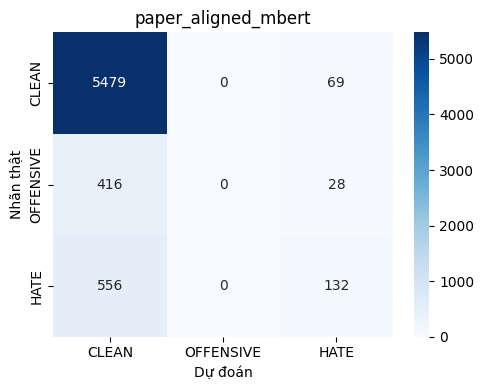

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]

controlled_mbert_shared_s42


,precision,recall,f1-score,support
CLEAN,0.917357,0.958363,0.937412,5548.00000
OFFENSIVE,0.470968,0.328829,0.387268,444.00000
HATE,0.608014,0.507267,0.553090,688.00000
accuracy,0.870060,0.870060,0.870060,0.87006
macro avg,0.665446,0.598153,0.625923,6680.00000
weighted avg,0.855826,0.870060,0.861263,6680.00000


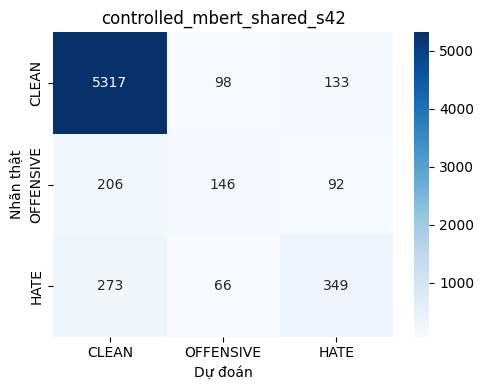

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]

controlled_phobert_shared_s42


,precision,recall,f1-score,support
CLEAN,0.933345,0.954037,0.943578,5548.000000
OFFENSIVE,0.517426,0.434685,0.472460,444.000000
HATE,0.655660,0.606105,0.629909,688.000000
accuracy,0.883683,0.883683,0.883683,0.883683
macro avg,0.702144,0.664942,0.681982,6680.000000
weighted avg,0.877100,0.883683,0.879958,6680.000000


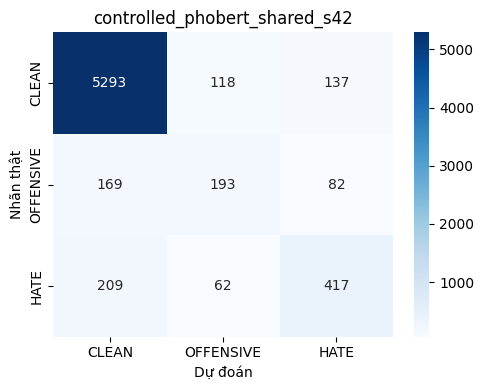

,name,model,policy,seed,macro_f1,weighted_f1,accuracy,f1_CLEAN,f1_OFFENSIVE,f1_HATE,dev_macro_f1,train_s,test_tokenize_s,test_predict_s,peak_gpu_gib
0,paper_aligned_mbert,google-bert/bert-base-multilingual-cased,paper_code_approx,4,0.400379,0.788135,0.839970,0.913243,0.000000,0.287895,0.405517,713.322222,2.199987,23.961945,3.361131
1,controlled_mbert_shared_s42,google-bert/bert-base-multilingual-cased,shared,42,0.625923,0.861263,0.870060,0.937412,0.387268,0.553090,0.660036,895.642000,3.742771,30.432692,3.360765
2,controlled_phobert_shared_s42,vinai/phobert-base-v2,shared,42,0.681982,0.879958,0.883683,0.943578,0.472460,0.629909,0.684272,565.099850,3.029419,21.200515,2.566568


PosixPath('vihsd_comparison/20261112_132650/predictions.csv')

In [8]:
assert hashlib.sha256(json.dumps(JOBS,sort_keys=True).encode()).hexdigest()==PLAN_HASH
assert len(trained)==len(JOBS)
save_json('locked_test_models.json',[dict(name=r['name'],selected_model=r['selected_model'],selection=r['selection']) for r in trained])
y_test=df_test.label.to_numpy(); predictions={}; test_rows=[]
for row in trained:
    tokenizer=AutoTokenizer.from_pretrained(row['selected_model'],use_fast=False)
    t=time.perf_counter(); ds=tokenized_frame(processed[row['policy']]['test'],None,tokenizer,row['max_length'])
    token_s=time.perf_counter()-t
    model=AutoModelForSequenceClassification.from_pretrained(row['selected_model']).to('cuda'); model.eval()
    loader=torch.utils.data.DataLoader(ds,batch_size=row['eval_batch'],shuffle=False,collate_fn=DataCollatorWithPadding(tokenizer))
    pred=[]; torch.cuda.synchronize(); t=time.perf_counter()
    with torch.inference_mode():
        for batch in loader:
            batch={k:v.to('cuda') for k,v in batch.items()}
            pred.extend(model(**batch).logits.argmax(-1).cpu().tolist())
    torch.cuda.synchronize(); infer_s=time.perf_counter()-t
    pred=np.asarray(pred); assert len(pred)==len(df_test)
    predictions[row['name']]=pred
    test_rows.append(dict(name=row['name'],model=row['model'],policy=row['policy'],seed=row['seed'],
                          **metrics(y_test,pred),dev_macro_f1=row['dev_metrics']['macro_f1'],
                          train_s=row['train_with_dev_checkpoint_s'],test_tokenize_s=token_s,test_predict_s=infer_s,
                          peak_gpu_gib=row['peak_gpu_allocated_gib']))
    output=pd.DataFrame(dict(id=df_test.id,text=df_test.text,ground_truth=y_test,predicted_label=pred))
    assert list(output.columns)==['id','text','ground_truth','predicted_label'] and output.id.is_unique
    output.to_csv(RUN_DIR/f"predictions_{row['name']}.csv",index=False,encoding='utf-8-sig')
    report=classification_report(y_test,pred,labels=LABELS,target_names=NAMES,zero_division=0,output_dict=True)
    save_json(f"report_{row['name']}.json",report)
    print(row['name']); display(pd.DataFrame(report).T)
    cm=confusion_matrix(y_test,pred,labels=LABELS)
    pd.DataFrame(cm,index=NAMES,columns=NAMES).to_csv(RUN_DIR/f"cm_{row['name']}.csv")
    plt.figure(figsize=(5,4)); sns.heatmap(cm,annot=True,fmt='d',xticklabels=NAMES,yticklabels=NAMES,cmap='Blues')
    plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title(row['name']); plt.tight_layout()
    plt.savefig(RUN_DIR/f"cm_{row['name']}.png",dpi=160); plt.show(); plt.close()
    del model,loader,ds; gc.collect(); torch.cuda.empty_cache()
comparison=pd.DataFrame(test_rows); comparison.to_csv(RUN_DIR/'test_comparison.csv',index=False)
display(comparison)
# File predictions.csv cố định là PhoBERT shared của seed đầu tiên; không chọn bằng điểm Test.
export_name=f'controlled_phobert_shared_s{SEEDS[0]}'
shutil.copy2(RUN_DIR/f'predictions_{export_name}.csv',RUN_DIR/'predictions.csv')

## 8. Phân tích đối chứng và khoảng bất định
Chỉ lấy hai mô hình **controlled/shared cùng seed** để diễn giải ảnh hưởng lựa chọn mô hình trong ngân sách này. Nhánh paper_aligned khác cả tiền xử lý, số epoch, seed và cách chọn checkpoint nên không dùng phép trừ giữa hai nhánh đó để quy nguyên nhân.

Bootstrap dưới đây lấy lại cùng chỉ số mẫu cho cả hai mô hình; khoảng 95% phản ánh biến động do mẫu Test cho một cặp mô hình cố định. Nó không bao gồm biến động huấn luyện, và giả định mẫu độc lập có thể bị ảnh hưởng bởi bình luận trùng/quan hệ giữa bình luận. Một khoảng dương không đủ để tuyên bố SOTA hoặc ý nghĩa thống kê trên mọi bối cảnh.

,seed,delta_macro_f1_phobert_minus_mbert,bootstrap95_low,bootstrap95_high
0,42,0.056059,0.038313,0.075154


,name,rows,macro_f1,weighted_f1,accuracy,f1_CLEAN,f1_OFFENSIVE,f1_HATE
0,controlled_mbert_shared_s42,5796,0.618519,0.852819,0.863009,0.933743,0.371814,0.550000
1,controlled_phobert_shared_s42,5796,0.675751,0.873091,0.877674,0.940493,0.454924,0.631837


macro_f1           weighted_f1      \
                                              mean std count        mean std   
model                                                                          
google-bert/bert-base-multilingual-cased  0.625923 NaN     1    0.861263 NaN   
vinai/phobert-base-v2                     0.681982 NaN     1    0.879958 NaN   

                                                accuracy              train_s  \
                                         count      mean std count       mean   
model                                                                           
google-bert/bert-base-multilingual-cased     1  0.870060 NaN     1  895.64200   
vinai/phobert-base-v2                        1  0.883683 NaN     1  565.09985   

                                                    
                                         std count  
model                                               
google-bert/bert-base-multilingual-cased NaN     1  
vinai/phobert-base-v2                    NaN     1

Chỉ có một seed: std chưa xác định, không diễn giải là 0 hoặc ổn định.


,source,accuracy,macro_f1
0,"Bài báo arXiv v4, m-BERT cased",0.8688,0.6269


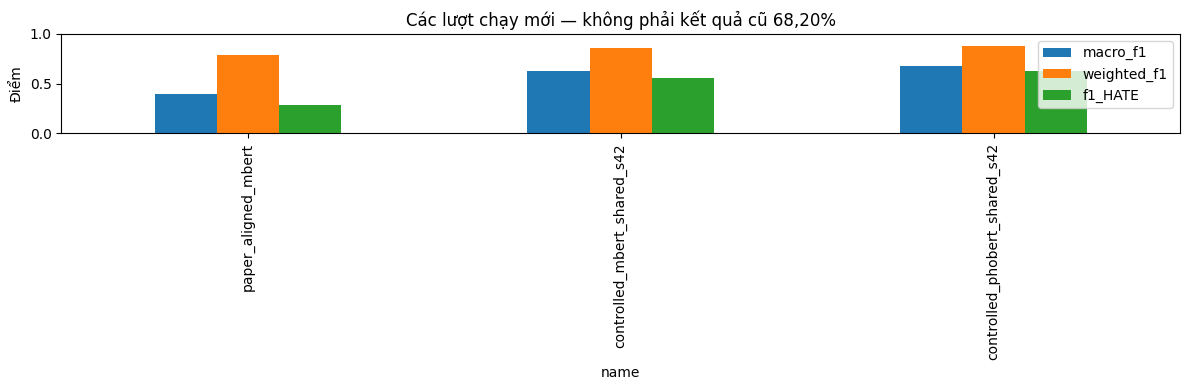

In [9]:
def paired_bootstrap(y,pa,pb,repeats=500,seed=123):
    rng=np.random.default_rng(seed); changes=[]
    for _ in range(repeats):
        ix=rng.integers(0,len(y),len(y))
        changes.append(metrics(y[ix],pb[ix])['macro_f1']-metrics(y[ix],pa[ix])['macro_f1'])
    return np.quantile(changes,[.025,.975]).tolist()
subset_rows=[]; contrasts=[]
for seed in SEEDS:
    a=f'controlled_mbert_shared_s{seed}'; b=f'controlled_phobert_shared_s{seed}'
    pa,pb=predictions[a],predictions[b]
    lo,hi=paired_bootstrap(y_test,pa,pb,BOOTSTRAP_REPEATS)
    contrasts.append(dict(seed=seed,delta_macro_f1_phobert_minus_mbert=metrics(y_test,pb)['macro_f1']-metrics(y_test,pa)['macro_f1'],
                          bootstrap95_low=lo,bootstrap95_high=hi))
    for name in [a,b]:
        if UNSEEN_MASK.any():
            subset_rows.append(dict(name=name,rows=int(UNSEEN_MASK.sum()),**metrics(y_test[UNSEEN_MASK],predictions[name][UNSEEN_MASK])))
display(pd.DataFrame(contrasts)); display(pd.DataFrame(subset_rows))
pd.DataFrame(contrasts).to_csv(RUN_DIR/'paired_contrasts.csv',index=False)
pd.DataFrame(subset_rows).to_csv(RUN_DIR/'test_unseen_text.csv',index=False)
controlled=comparison[comparison.policy.eq('shared')].copy()
summary=controlled.groupby('model')[['macro_f1','weighted_f1','accuracy','train_s']].agg(['mean','std','count'])
display(summary); summary.to_csv(RUN_DIR/'controlled_seed_summary.csv')
if len(SEEDS)==1: print('Chỉ có một seed: std chưa xác định, không diễn giải là 0 hoặc ổn định.')
if RUN_ABLATION:
    display(comparison[comparison.policy.isin(['shared','minimal'])][['name','policy','seed','macro_f1','weighted_f1']])
# Mốc bài báo là tham khảo, tách khỏi bảng đối chứng cùng điều kiện.
reference=pd.DataFrame([dict(source='Bài báo arXiv v4, m-BERT cased',accuracy=.8688,macro_f1=.6269)])
display(reference)
comparison.set_index('name')[['macro_f1','weighted_f1','f1_HATE']].plot.bar(ylim=(0,1),figsize=(12,4))
plt.ylabel('Điểm'); plt.title('Các lượt chạy mới — không phải kết quả cũ 68,20%'); plt.tight_layout()
plt.savefig(RUN_DIR/'comparison.png',dpi=160); plt.show(); plt.close()

## 9. Cách kết luận và bàn giao
Sau khi chạy, điền số thực tế từ `paired_contrasts.csv`:

> Trong cùng split, chính sách tiền xử lý và ngân sách huấn luyện đã công bố, m-BERT đạt MF1 … và PhoBERT đạt MF1 …, chênh lệch … điểm phần trăm. Kết quả này hỗ trợ/không hỗ trợ lợi ích của lựa chọn PhoBERT trong thiết lập đang xét. Khác tokenizer và tiền huấn luyện là thành phần của sự thay mô hình; chưa chứng minh một kiến trúc mới do nhóm đề xuất.

Với nhánh `paper_aligned_mbert`, ghi điểm mới và chênh lệch với 62,69%, kèm các sai khác ở mục 1. Không gọi chênh lệch là thất bại môi trường hoặc chỉnh tham số theo Test để ép đạt mốc. Không dùng 68,20% cũ để điền thay cho kết quả mới.

`test_unseen_text.csv` là kiểm tra độ nhạy, không phải bộ benchmark độc lập. Muốn kết luận về chống trùng, cần thiết kế split theo nhóm ở vòng nghiên cứu riêng. Dữ liệu Test đã được nhóm xem trước nên đây là đối chứng bổ sung trên benchmark đã biết, không phải thử nghiệm mù trên dữ liệu chưa từng nhìn thấy.

Gói báo cáo gồm manifest/hash, phiên bản thư viện/GPU, kế hoạch khóa, cấu hình và revision mô hình, lịch sử train, checkpoint được chọn, điểm từng lớp, ma trận nhầm lẫn, CSV dự đoán, thời gian, đối chứng và khoảng bootstrap. Không xuất điểm giả nếu một job thất bại. Nếu gián đoạn, chạy lại notebook tạo thư mục lượt chạy mới; không dùng biến của lượt dở để ghép kết quả.

In [10]:
# Xuất báo cáo nhẹ, bỏ trọng số pretrained/checkpoint để ZIP không quá nặng.
import zipfile
report_zip=ROOT/f'{RUN_DIR.name}_reports.zip'
with zipfile.ZipFile(report_zip,'w',zipfile.ZIP_DEFLATED) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and 'selected_model' not in p.parts and p.suffix in {'.json','.csv','.png','.txt'}:
            z.write(p,p.relative_to(RUN_DIR))
print('Báo cáo:',report_zip.resolve())
print('Trọng số đã chọn vẫn ở các thư mục selected_model; lưu riêng nếu cần.')
# from google.colab import files
# files.download(str(report_zip))

Báo cáo: /content/vihsd_comparison/20261112_132650_reports.zip
Trọng số đã chọn vẫn ở các thư mục selected_model; lưu riêng nếu cần.
